In [ ]:
"""Run AGREED on Default-Credit and plot the local and global group importance"""

from IPython.display import display
import os
import time
import matplotlib.pyplot as plt
from matplotlib import rc

rc("font", **{"family": "serif", "serif": ["Computer Modern Roman"], "size": 20})
rc("text", usetex=True)
import numpy as np
from joblib import load
from pyfd.decompositions import get_components_ebm
from pyfd.decompositions import get_interventional_from_anchored, get_PDP_PFI_importance
from pyfd.shapley import shap_from_decomposition, get_SHAP_importance
from pyfd.plots import bar, partial_dependence_plot

# Local
from utils import custom_train_test_split

from agreed.dataset.tabular.factory import get_data_credit
from agreed.explainers.tabular.grouping import TabularAGREED


In [2]:
np.random.seed(42)
X, y, features = get_data_credit()
task = "classification"

x_train, x_test, y_train, y_test = custom_train_test_split(X, y.ravel(), task)
background = x_test[np.random.choice(x_test.shape[0], 1000, replace=False)]
N, d = background.shape

# Save the model for later
model = load(os.path.join("models", "ebm_default_credit.joblib"))
display(model)
display(model.score(x_test, y_test))


ExplainableBoostingClassifier(interactions=0.4, max_interaction_bins=32,
                              outer_bags=25)

0.8079359786595531

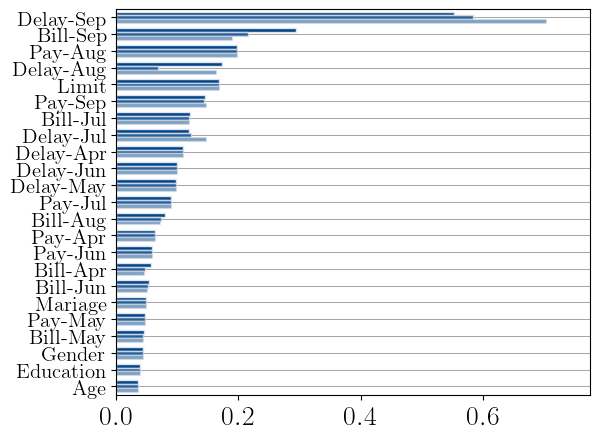

In [3]:
decomposition = get_components_ebm(
    model, background, background, features, anchored=True
)
shap_values = shap_from_decomposition(get_interventional_from_anchored(decomposition))
I_PDP, I_PFI = get_PDP_PFI_importance(decomposition)
I_SHAP = get_SHAP_importance(shap_values)

bar([I_PFI, I_SHAP, I_PDP], feature_labels=features.names())
plt.savefig(os.path.join("results", "GFI_ebm_default_credit.pdf"), bbox_inches="tight")


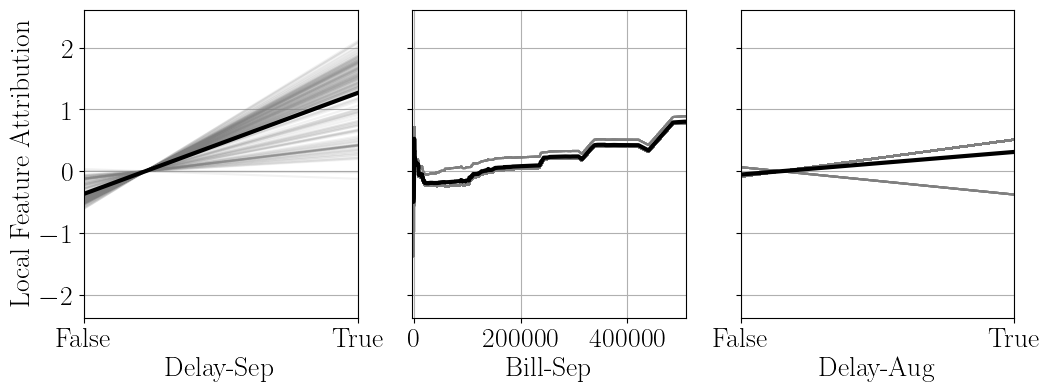

In [4]:
partial_dependence_plot(
    decomposition, background, features, idxs=[2, 3, 8], figsize=(12, 4), centered=True
)
plt.savefig(os.path.join("results", "LFA_ebm_default_credit.pdf"), bbox_inches="tight")


In [5]:
start = time.time()
partition = TabularAGREED(
    model.decision_function,
    background,
    threshold=0.1,
    max_group_size=3,
)
display(f"Took {time.time() - start: .2f} seconds")
features_to_group = [group for group in partition.Imap_inv if len(group) > 1]
grouped_features = features.group(features_to_group)
grouped_features.summary()


'Took  54.72 seconds'

|Idx|        Name        |        Type        |    Card    |      Groups      |
-------------------------------------------------------------------------------
| 0 | Limit              | num                | inf        | [0]              |
| 1 | Age                | num_int            | 59         | [1]              |
| 2 | Delay-Jul          | bool               | 2          | [4]              |
| 3 | Delay-Jun          | bool               | 2          | [5]              |
| 4 | Delay-May          | bool               | 2          | [6]              |
| 5 | Delay-Apr          | bool               | 2          | [7]              |
| 6 | Bill-Aug           | sparse_num         | inf        | [9]              |
| 7 | Bill-Jul           | sparse_num         | inf        | [10]             |
| 8 | Bill-Jun           | sparse_num         | inf        | [11]             |
| 9 | Bill-May           | sparse_num         | inf        | [12]             |
| 10| Bill-Apr           | sparse_num   

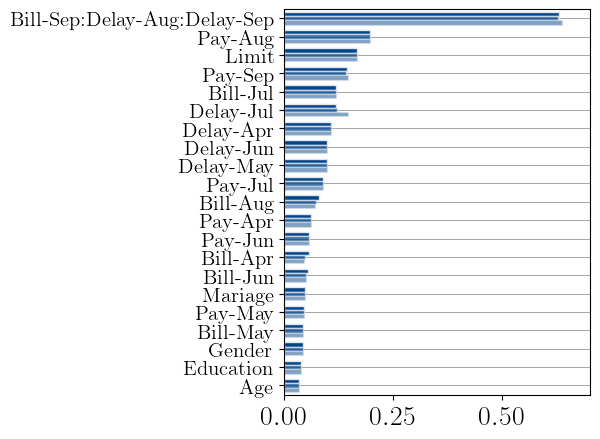

In [6]:
grouped_decomposition = get_components_ebm(
    model, background, background, grouped_features, anchored=True
)
grouped_shap_values = shap_from_decomposition(
    get_interventional_from_anchored(grouped_decomposition)
)
grouped_I_PDP, grouped_I_PFI = get_PDP_PFI_importance(grouped_decomposition)
grouped_I_SHAP = get_SHAP_importance(grouped_shap_values)

bar(
    [grouped_I_PFI, grouped_I_SHAP, grouped_I_PDP],
    feature_labels=grouped_features.names(),
)
plt.savefig(
    os.path.join("results", "grouped_GFI_ebm_default_credit.pdf"), bbox_inches="tight"
)



In [7]:
def get_region(X):
    region = np.zeros(X.shape[0])
    region[(X[:, 2] == 0) & (X[:, 3] == 0)] = 0
    region[(X[:, 2] == 0) & (X[:, 3] == 1)] = 1
    region[(X[:, 2] == 1) & (X[:, 3] == 0)] = 2
    region[(X[:, 2] == 1) & (X[:, 3] == 1)] = 3
    return region


labels = [
    r"noDelay-Aug \& noDelay-Sep",
    r"Delay-Aug \& noDelay-Sep",
    r"noDelay-Aug \& Delay-Sep",
    r"Delay-Aug \& Delay-Sep",
]
large_background = x_train
regions = get_region(large_background)
grouped_decomposition = get_components_ebm(
    model, large_background, large_background, grouped_features, anchored=False
)
joint_effect = grouped_decomposition[(20,)]


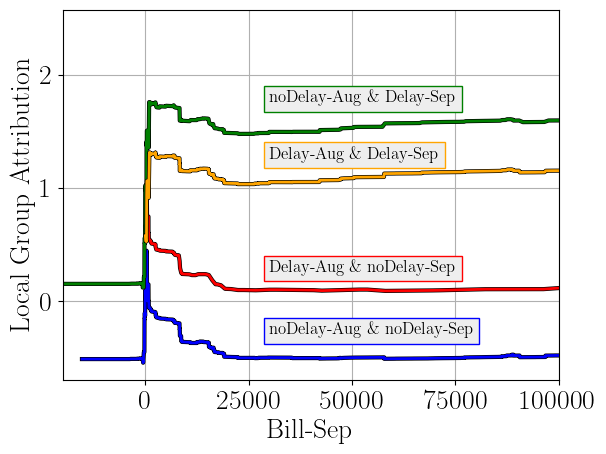

In [8]:
COLORS = ["blue", "red", "green", "orange", "violet", "brown", "cyan", "olive"]
region_label_y_loc = [-0.3, 0.25, 1.75, 1.25]
plt.figure()
for r in range(4):
    subset = np.where(regions == r)[0]
    color = COLORS[r]
    background_subset = large_background[subset]
    joint_effect_subset = joint_effect[subset]
    # Plot the PDP/ICE curves
    sorted_idx = np.argsort(background_subset[:, 8])
    # For each group plot the anchored components in color
    H = joint_effect_subset[sorted_idx]
    x = background_subset[sorted_idx, 8]
    # Plot at most n_curves ICE curves
    plt.plot(x, H, "k", linewidth=3)
    plt.plot(x, H, color, linewidth=2)
    plt.text(
        30000,
        region_label_y_loc[r],
        labels[r],
        fontdict={"size": 12},
        bbox=dict(facecolor="#EEEEEE", alpha=1, edgecolor=COLORS[r]),
    )
plt.xlim(-20000, 100000)
plt.xlabel("Bill-Sep")
plt.ylabel("Local Group Attribution")
plt.grid("on")
plt.savefig(
    os.path.join("results", "grouped_LFA_ebm_default_credit.pdf"), bbox_inches="tight"
)


In [9]:
# [Bonus] We could further decompose the joint attribution of day-month-contact
# three main effects + three pairwise interactions + a three-way interaction
# joint effect = h_1 + h_2 + h_3 + h_12 + h_23 + h_13 + h_123
decomposition = get_components_ebm(
    model, large_background, large_background, features, anchored=False
)
# Since this model only involves two-way interactions, we need visualize at
# most 6 functions. To improve interpretability, we can post-process the components
# by centering them.
centered_decomposition = {}
centered_decomposition[()] = decomposition[()]
for key, component in decomposition.items():
    if len(key) > 0:
        centered_decomposition[key] = component
        mean_component = component.mean()
        centered_decomposition[key] = decomposition[key] - mean_component
        centered_decomposition[()] = decomposition[()] + mean_component
display(centered_decomposition.keys())


dict_keys([(), (0,), (1,), (2,), (3,), (2, 3), (4,), (2, 4), (5,), (6,), (7,), (8,), (2, 8), (9,), (2, 9), (10,), (2, 10), (11,), (2, 11), (12,), (2, 12), (13,), (2, 13), (14,), (2, 14), (15,), (2, 15), (16,), (17,), (18,), (19,), (20,), (21,), (22,)])

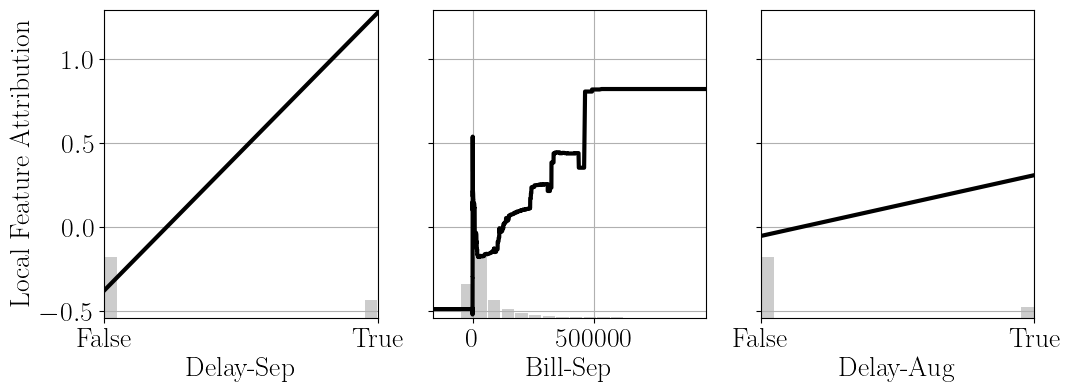

In [10]:
partial_dependence_plot(
    centered_decomposition, large_background, features, idxs=[2, 3, 8], figsize=(12, 4)
)


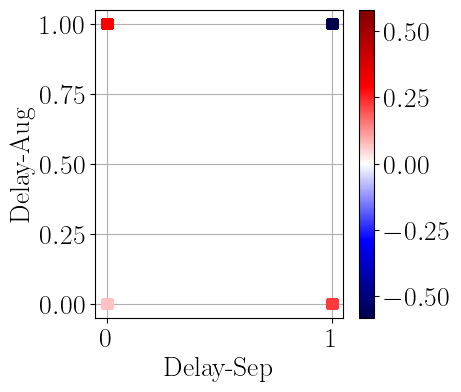

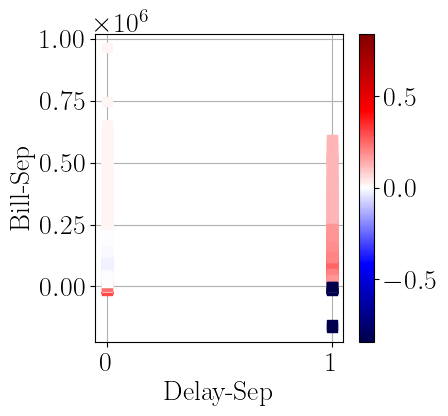

In [11]:
from itertools import combinations
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import matplotlib.cm as cm


# Plot the joint effect of three variables at the same time
for i, j in combinations([2, 3, 8], 2):
    # Plot at most n_curves ICE curves
    if (i, j) in centered_decomposition.keys():
        normalizer = CenteredNorm(0, np.abs(centered_decomposition[(i, j)]).max())
        fig, axes = plt.subplots(1, 1, figsize=(4, 4))
        axes.scatter(
            large_background[:, i],
            large_background[:, j],
            c=centered_decomposition[(i, j)],
            marker="s",
            s=50,
            cmap="seismic",
            norm=normalizer,
            zorder=2,
        )
        axes.set_xlabel(features.names()[i])
        axes.set_ylabel(features.names()[j])
        axes.grid("on", zorder=-1)
        fig.colorbar(
            ax=axes, mappable=cm.ScalarMappable(norm=normalizer, cmap="seismic")
        )
plt.show()